# STEP 2 - Coarse Overview

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from numba import njit, prange
from tqdm import tqdm
from scipy.signal import correlate
import os
import sys

module_path = os.path.abspath(os.path.join('..'))
if module_path not in sys.path:
    sys.path.append(module_path)

from GLOBAL.ground_truths import *
from GLOBAL.torque import *
from GLOBAL.filters import *

with np.load("../GLOBAL/data.npz") as data:
    x_data=data['x_data']
    y_data=data['y_data']


# View 1

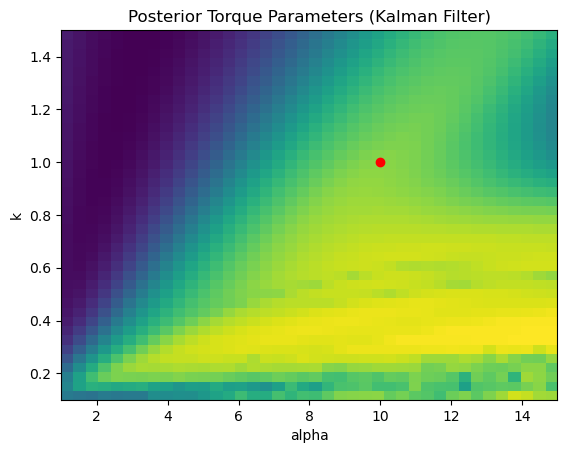

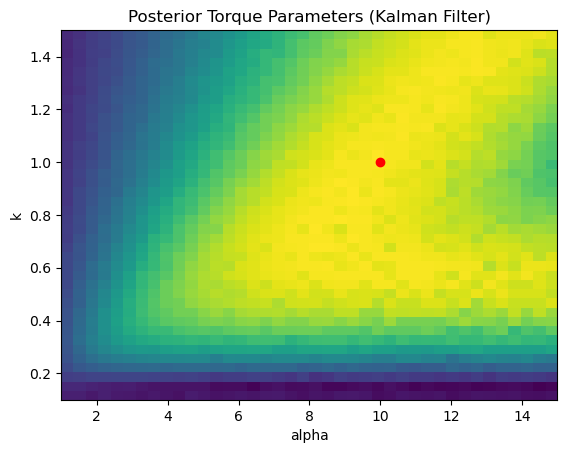

In [8]:
alpha_min = 0.1 * ALPHA
alpha_max = 1.5 * ALPHA
k_min = 0.1 * K
k_max = 1.5 * K

resolution = 40

alpha_grid = np.linspace(alpha_min, alpha_max, resolution)
k_grid = np.linspace(k_min, k_max, resolution)

ALPHA_GRID, K_GRID = np.meshgrid(alpha_grid, k_grid)
shape_chunk = ALPHA_GRID.shape
ALPHA_GRID = ALPHA_GRID.flatten()
K_GRID = K_GRID.flatten()

params = np.stack((ALPHA_GRID, K_GRID), axis=1)

max_angle = 1000000 * np.pi / 180

''' Kalman Filter '''

logl, _, _ = calc_logl_core_kalman(x_data, y_data, dt,
                                   PE, DT, DR, FORCE_STRENGTH,
                                   params, torque_limit=max_angle)
logl = logl.reshape(shape_chunk)

P = np.exp(logl - np.max(logl))
P /= np.sum(P)
P_flat = np.sort(P.flatten())
CDF = np.cumsum(P_flat)
CDF = CDF / CDF[-1]
perc = 99
idx = np.argmax(CDF > (100 - perc) / 100)

plt.imshow(logl, extent=(alpha_min, alpha_max, k_min, k_max), origin='lower', aspect='auto')
#plt.contour(alpha_grid, k_grid, P, levels=[P_flat[idx]], linestyles='--')
plt.plot(ALPHA, K, 'ro', label='Ground Truth')
plt.xlabel('alpha')
plt.ylabel('k')
plt.title('Posterior Torque Parameters (Kalman Filter)')
plt.savefig('kalman1.png', dpi=300)
plt.show()

''' Particle Filter '''

logl, _, _ = calc_logl_core(x_data, y_data, dt,
                                   PE, DT, DR, FORCE_STRENGTH,
                                   params, torque_limit=max_angle,
                                   n_particles=10
                                   )
logl = logl.reshape(shape_chunk)

P = np.exp(logl - np.max(logl))
P /= np.sum(P)
P_flat = np.sort(P.flatten())
CDF = np.cumsum(P_flat)
CDF = CDF / CDF[-1]
perc = 99
idx = np.argmax(CDF > (100 - perc) / 100)

plt.imshow(logl, extent=(alpha_min, alpha_max, k_min, k_max), origin='lower', aspect='auto')
#plt.contour(alpha_grid, k_grid, P, levels=[P_flat[idx]], linestyles='--')
plt.plot(ALPHA, K, 'ro', label='Ground Truth')
plt.xlabel('alpha')
plt.ylabel('k')
plt.title('Posterior Torque Parameters (Kalman Filter)')
plt.savefig('particle1.png', dpi=300)
plt.show()

# View 2

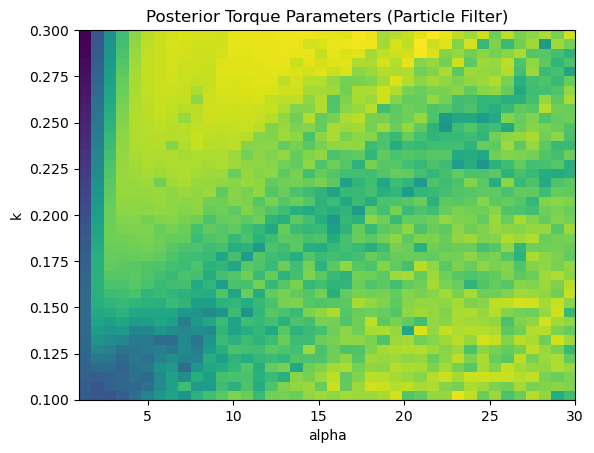

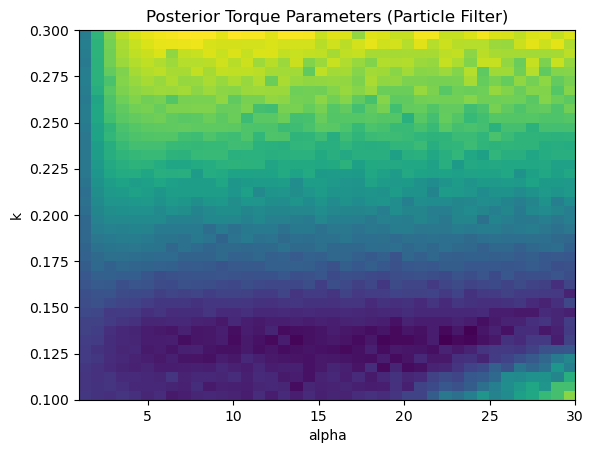

In [9]:
alpha_min = 0.1 * ALPHA
alpha_max = 3 * ALPHA
k_min = 0.1 * K
k_max = 0.3

alpha_grid = np.linspace(alpha_min, alpha_max, resolution)
k_grid = np.linspace(k_min, k_max, resolution)

ALPHA_GRID, K_GRID = np.meshgrid(alpha_grid, k_grid)
shape_chunk = ALPHA_GRID.shape
ALPHA_GRID = ALPHA_GRID.flatten()
K_GRID = K_GRID.flatten()

params = np.stack((ALPHA_GRID, K_GRID), axis=1)

max_angle = 1000000 * np.pi / 180

''' Kalman Filter '''

logl, _, _ = calc_logl_core_kalman(x_data, y_data, dt,
                                   PE, DT, DR, FORCE_STRENGTH,
                                   params, torque_limit=max_angle)
logl = logl.reshape(shape_chunk)

P = np.exp(logl - np.max(logl))
P /= np.sum(P)
P_flat = np.sort(P.flatten())
CDF = np.cumsum(P_flat)
CDF = CDF / CDF[-1]
perc = 99
idx = np.argmax(CDF > (100 - perc) / 100)

plt.imshow(logl, extent=(alpha_min, alpha_max, k_min, k_max), origin='lower', aspect='auto')
#plt.contour(alpha_grid, k_grid, P, levels=[P_flat[idx]], linestyles='--')
#plt.plot(ALPHA, K, 'ro', label='Ground Truth')
plt.xlabel('alpha')
plt.ylabel('k')
plt.title('Posterior Torque Parameters (Particle Filter)')
plt.savefig('kalman2.png', dpi=300)
plt.show()

''' Particle Filter '''

logl, _, _ = calc_logl_core(x_data, y_data, dt,
                                   PE, DT, DR, FORCE_STRENGTH,
                                   params, torque_limit=max_angle,
                                   n_particles=10
                                   )
logl = logl.reshape(shape_chunk)

P = np.exp(logl - np.max(logl))
P /= np.sum(P)
P_flat = np.sort(P.flatten())
CDF = np.cumsum(P_flat)
CDF = CDF / CDF[-1]
perc = 99
idx = np.argmax(CDF > (100 - perc) / 100)

plt.imshow(logl, extent=(alpha_min, alpha_max, k_min, k_max), origin='lower', aspect='auto')
#plt.contour(alpha_grid, k_grid, P, levels=[P_flat[idx]], linestyles='--')
#plt.plot(ALPHA, K, 'ro', label='Ground Truth')
plt.xlabel('alpha')
plt.ylabel('k')
plt.title('Posterior Torque Parameters (Particle Filter)')
plt.savefig('particle2.png', dpi=300)
plt.show()

# View 3

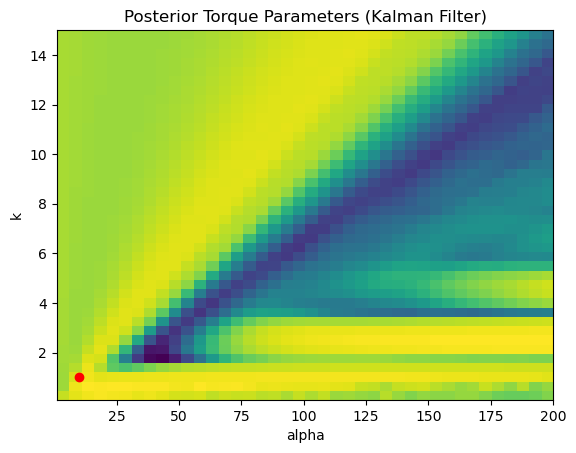

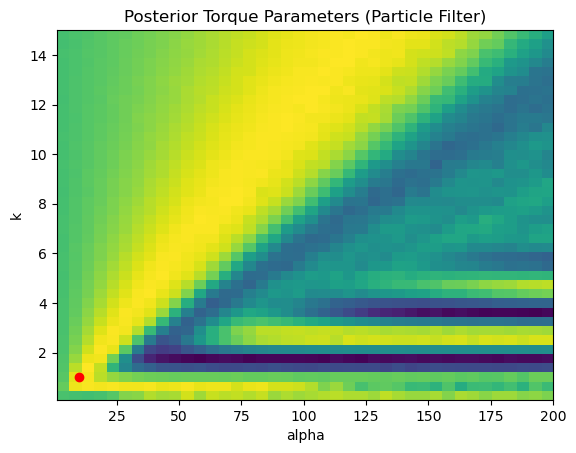

In [10]:
alpha_min = 0.1 * ALPHA
alpha_max = 20 * ALPHA
k_min = 0.1 * K
k_max = 15 * K

alpha_grid = np.linspace(alpha_min, alpha_max, resolution)
k_grid = np.linspace(k_min, k_max, resolution)

ALPHA_GRID, K_GRID = np.meshgrid(alpha_grid, k_grid)
shape_chunk = ALPHA_GRID.shape
ALPHA_GRID = ALPHA_GRID.flatten()
K_GRID = K_GRID.flatten()

params = np.stack((ALPHA_GRID, K_GRID), axis=1)

max_angle = 1000000 * np.pi / 180

''' Kalman Filter '''

logl, _, _ = calc_logl_core_kalman(x_data, y_data, dt,
                                   PE, DT, DR, FORCE_STRENGTH,
                                   params, torque_limit=max_angle)
logl = logl.reshape(shape_chunk)

P = np.exp(logl - np.max(logl))
P /= np.sum(P)
P_flat = np.sort(P.flatten())
CDF = np.cumsum(P_flat)
CDF = CDF / CDF[-1]
perc = 99
idx = np.argmax(CDF > (100 - perc) / 100)

plt.imshow(logl, extent=(alpha_min, alpha_max, k_min, k_max), origin='lower', aspect='auto')
#plt.contour(alpha_grid, k_grid, P, levels=[P_flat[idx]], linestyles='--')
plt.plot(ALPHA, K, 'ro', label='Ground Truth')
plt.xlabel('alpha')
plt.ylabel('k')
plt.title('Posterior Torque Parameters (Kalman Filter)')
plt.savefig('kalman3.png', dpi=300)
plt.show()

''' Particle Filter '''

logl, _, _ = calc_logl_core(x_data, y_data, dt,
                                   PE, DT, DR, FORCE_STRENGTH,
                                   params, torque_limit=max_angle,
                                   n_particles=10
                                   )
logl = logl.reshape(shape_chunk)

P = np.exp(logl - np.max(logl))
P /= np.sum(P)
P_flat = np.sort(P.flatten())
CDF = np.cumsum(P_flat)
CDF = CDF / CDF[-1]
perc = 99
idx = np.argmax(CDF > (100 - perc) / 100)

plt.imshow(logl, extent=(alpha_min, alpha_max, k_min, k_max), origin='lower', aspect='auto')
#plt.contour(alpha_grid, k_grid, P, levels=[P_flat[idx]], linestyles='--')
plt.plot(ALPHA, K, 'ro', label='Ground Truth')
plt.xlabel('alpha')
plt.ylabel('k')
plt.title('Posterior Torque Parameters (Particle Filter)')
plt.savefig('particle3.png', dpi=300)
plt.show()

# View 4

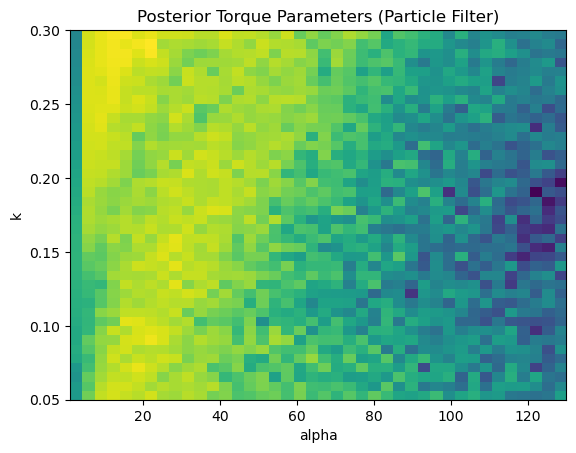

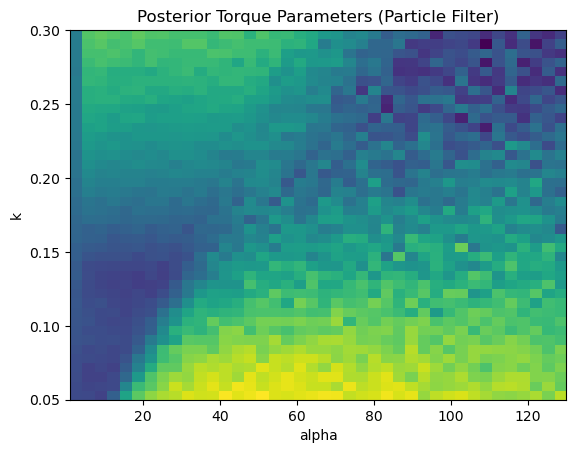

In [11]:
alpha_min = 0.1 * ALPHA
alpha_max = 13 * ALPHA
k_min = 0.05 * K
k_max = 0.3

alpha_grid = np.linspace(alpha_min, alpha_max, resolution)
k_grid = np.linspace(k_min, k_max, resolution)

ALPHA_GRID, K_GRID = np.meshgrid(alpha_grid, k_grid)
shape_chunk = ALPHA_GRID.shape
ALPHA_GRID = ALPHA_GRID.flatten()
K_GRID = K_GRID.flatten()

params = np.stack((ALPHA_GRID, K_GRID), axis=1)

max_angle = 1000000 * np.pi / 180

''' Kalman Filter '''

logl, _, _ = calc_logl_core_kalman(x_data, y_data, dt,
                                   PE, DT, DR, FORCE_STRENGTH,
                                   params, torque_limit=max_angle)
logl = logl.reshape(shape_chunk)

P = np.exp(logl - np.max(logl))
P /= np.sum(P)
P_flat = np.sort(P.flatten())
CDF = np.cumsum(P_flat)
CDF = CDF / CDF[-1]
perc = 99
idx = np.argmax(CDF > (100 - perc) / 100)

plt.imshow(logl, extent=(alpha_min, alpha_max, k_min, k_max), origin='lower', aspect='auto')
#plt.contour(alpha_grid, k_grid, P, levels=[P_flat[idx]], linestyles='--')
#plt.plot(ALPHA, K, 'ro', label='Ground Truth')
plt.xlabel('alpha')
plt.ylabel('k')
plt.title('Posterior Torque Parameters (Particle Filter)')
plt.savefig('kalman2.png', dpi=300)
plt.show()

''' Particle Filter '''

logl, _, _ = calc_logl_core(x_data, y_data, dt,
                                   PE, DT, DR, FORCE_STRENGTH,
                                   params, torque_limit=max_angle,
                                   n_particles=10
                                   )
logl = logl.reshape(shape_chunk)

P = np.exp(logl - np.max(logl))
P /= np.sum(P)
P_flat = np.sort(P.flatten())
CDF = np.cumsum(P_flat)
CDF = CDF / CDF[-1]
perc = 99
idx = np.argmax(CDF > (100 - perc) / 100)

plt.imshow(logl, extent=(alpha_min, alpha_max, k_min, k_max), origin='lower', aspect='auto')
#plt.contour(alpha_grid, k_grid, P, levels=[P_flat[idx]], linestyles='--')
#plt.plot(ALPHA, K, 'ro', label='Ground Truth')
plt.xlabel('alpha')
plt.ylabel('k')
plt.title('Posterior Torque Parameters (Particle Filter)')
plt.savefig('particle2.png', dpi=300)
plt.show()

# View 5

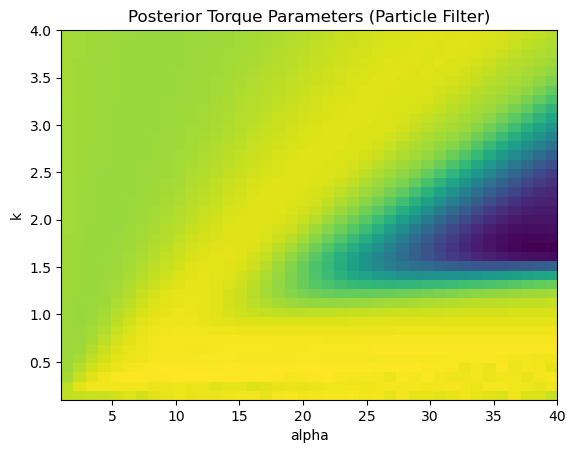

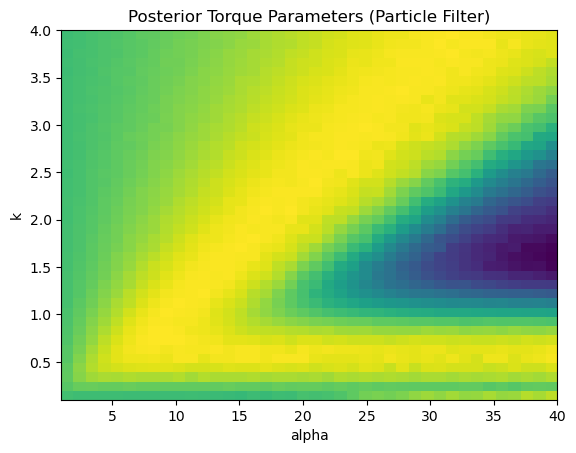

In [12]:
alpha_min = 0.1 * ALPHA
alpha_max = 4 * ALPHA
k_min = 0.1 * K
k_max = 4 * K

alpha_grid = np.linspace(alpha_min, alpha_max, resolution)
k_grid = np.linspace(k_min, k_max, resolution)

ALPHA_GRID, K_GRID = np.meshgrid(alpha_grid, k_grid)
shape_chunk = ALPHA_GRID.shape
ALPHA_GRID = ALPHA_GRID.flatten()
K_GRID = K_GRID.flatten()

params = np.stack((ALPHA_GRID, K_GRID), axis=1)

max_angle = 1000000 * np.pi / 180

''' Kalman Filter '''

logl, _, _ = calc_logl_core_kalman(x_data, y_data, dt,
                                   PE, DT, DR, FORCE_STRENGTH,
                                   params, torque_limit=max_angle)
logl = logl.reshape(shape_chunk)

P = np.exp(logl - np.max(logl))
P /= np.sum(P)
P_flat = np.sort(P.flatten())
CDF = np.cumsum(P_flat)
CDF = CDF / CDF[-1]
perc = 99
idx = np.argmax(CDF > (100 - perc) / 100)

plt.imshow(logl, extent=(alpha_min, alpha_max, k_min, k_max), origin='lower', aspect='auto')
#plt.contour(alpha_grid, k_grid, P, levels=[P_flat[idx]], linestyles='--')
#plt.plot(ALPHA, K, 'ro', label='Ground Truth')
plt.xlabel('alpha')
plt.ylabel('k')
plt.title('Posterior Torque Parameters (Particle Filter)')
plt.savefig('kalman2.png', dpi=300)
plt.show()

''' Particle Filter '''

logl, _, _ = calc_logl_core(x_data, y_data, dt,
                                   PE, DT, DR, FORCE_STRENGTH,
                                   params, torque_limit=max_angle,
                                   n_particles=10
                                   )
logl = logl.reshape(shape_chunk)

P = np.exp(logl - np.max(logl))
P /= np.sum(P)
P_flat = np.sort(P.flatten())
CDF = np.cumsum(P_flat)
CDF = CDF / CDF[-1]
perc = 99
idx = np.argmax(CDF > (100 - perc) / 100)

plt.imshow(logl, extent=(alpha_min, alpha_max, k_min, k_max), origin='lower', aspect='auto')
#plt.contour(alpha_grid, k_grid, P, levels=[P_flat[idx]], linestyles='--')
#plt.plot(ALPHA, K, 'ro', label='Ground Truth')
plt.xlabel('alpha')
plt.ylabel('k')
plt.title('Posterior Torque Parameters (Particle Filter)')
plt.savefig('particle2.png', dpi=300)
plt.show()